# Residuals for Cox regression model

After fitting a Cox regression model we check it with residuals. There are several kinds, and each one answers a different question:

- **Cox-Snell** residuals: is the model, as a whole, adequate?
- **Martingale** and **deviance** residuals: which individuals are badly fitted?
- **Schoenfeld** residuals: are the hazards proportional?

The data are the times, in days, to the first infection of 13 patients on dialysis, with their age and sex (1 = male, 2 = female). One time is censored.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
from statsmodels.nonparametric.smoothers_lowess import lowess

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/dialysis_infection.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
DatOriginal.head()

,time,status,age,sex
0,8,1,28,1
1,15,1,44,2
2,22,1,32,1
3,24,1,16,2
4,30,1,10,1


## The model

In [5]:
Model = CoxPHFitter().fit(DatOriginal, "time", "status")

In [6]:
Model.print_summary()

<lifelines.CoxPHFitter: fitted with 13 total observations, 1 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 13
number of events observed = 12
   partial log-likelihood = -17.23
         time fit was run = 2026-10-13 02:30:53 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        0.03      1.03      0.03           -0.02            0.08                0.98                1.09
sex       -2.71      0.07      1.10           -4.86           -0.56                0.01                0.57

           cmp to     z    p  -log2(p)
covariate                             
age          0.00  1.16 0.25      2.02
sex          0.00 -2.47 0.01      6.22
---
Concordance = 0.70
Partial AIC = 38.47
log-likelihood ratio test = 6.48 on 2 df
-log2(p) of ll-ratio test = 4.67

## The residuals

Martingale, deviance, Schoenfeld and Scaled Schoenfeld residuals

In [7]:
rM = Model.compute_residuals(DatOriginal, 'martingale')
rD = Model.compute_residuals(DatOriginal, 'deviance')
rS = Model.compute_residuals(DatOriginal, 'schoenfeld')
rSS = Model.compute_residuals(DatOriginal, 'scaled_schoenfeld')

Cox-Snell residuals. They are the estimated cumulative hazard of each individual at their own time, $r_{C_i}=\hat H_0(t_i)\exp(\hat\beta^Tx_i)$, and the martingale residuals are $r_{M_i}=\delta_i-r_{C_i}$, where $\delta_i$ is 1 for an event and 0 for a censored time.

In [8]:
rC = pd.DataFrame(
    {'time':rM['time'], 'status':rM['status'], 'cox_snell':-rM['martingale']+rM['status']}
)

Functions for the plots. In all of them a filled point is an infection and an open point is the censored time.

In [9]:
def PlotPoints(ax, x, y, status):
    status = np.asarray(status, dtype=bool)
    x, y = np.asarray(x), np.asarray(y)
    ax.plot(x[status], y[status], 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5,
            label='Infection')
    ax.plot(x[~status], y[~status], 'o', markerfacecolor='white', markersize=9, markeredgecolor=point_color,
            markeredgewidth=1.5, label='Censored')

def LabelPoints(ax, x, y, labels, which):
    # Write the label of the selected observations next to their points
    x, y = np.asarray(x), np.asarray(y)
    for i in which:
        ax.annotate(str(labels[i]), (x[i], y[i]), xytext=(8, 6), textcoords='offset points', color=ref_color)

## Cox-Snell plot

If the model is correct, the Cox-Snell residuals behave like a censored sample from a unit exponential distribution, whose cumulative hazard is $H(r)=r$. So we estimate the cumulative hazard of the residuals with the Kaplan-Meier estimator and plot it against the residuals: the points should follow the line with slope 1 through the origin. The same must happen in the logarithmic scale.

In [10]:
# Fit Kaplan-Meier estimator for Cox-Snell residuals
Surv_rC = KaplanMeierFitter()
Surv_rC.fit(rC['cox_snell'], rC['status'])

# Estimate the cumulative hazard from the KM estimator
# (the estimator is zero after the largest residual, there the cumulative hazard is not defined)
KM_estimate = Surv_rC.survival_function_['KM_estimate']
rC_KM = (-np.log(KM_estimate.where(KM_estimate > 0))).reset_index().drop_duplicates()
rC_KM = rC_KM.rename({'timeline':'cox_snell', 'KM_estimate':'cumulative_hazard'}, axis=1)
rC_KM = rC_KM.reset_index(drop=True)

rC_KM = pd.merge(rC, rC_KM)

In [11]:
rC_KM.round(4)

,time,status,cox_snell,cumulative_hazard
0,8.0,True,0.2800,0.3801
1,15.0,True,0.0723,0.0800
2,22.0,True,1.2139,1.0733
3,24.0,True,0.0843,0.1671
4,30.0,True,1.5060,1.7664
5,54.0,False,0.2646,0.2624
6,119.0,True,0.2355,0.2624
7,141.0,True,0.4837,0.5137
8,185.0,True,1.4379,1.3610
9,292.0,True,1.2123,0.8502


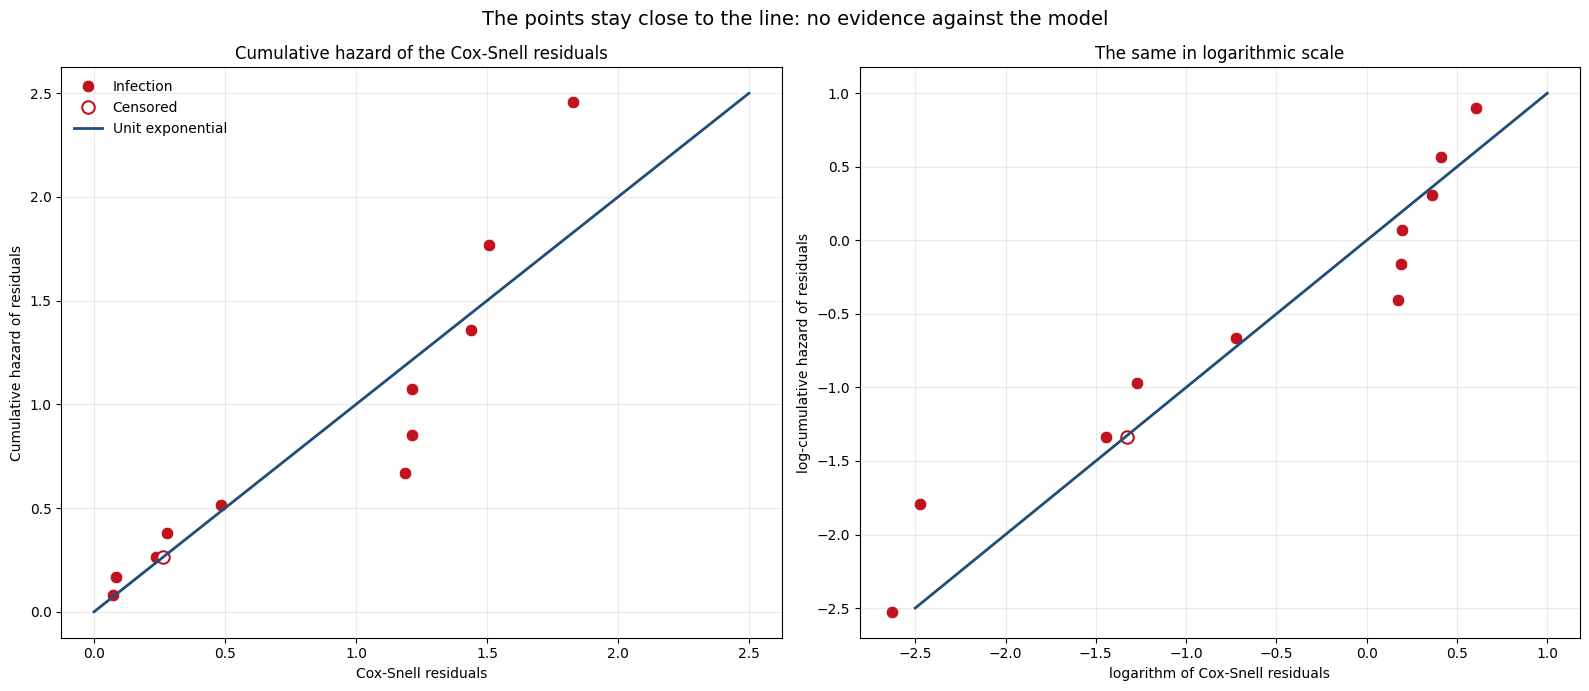

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

PlotPoints(axes[0], rC_KM['cox_snell'], rC_KM['cumulative_hazard'], rC_KM['status'])
axes[0].plot([0, 2.5], [0, 2.5], color=line_color, lw=2, label='Unit exponential')
axes[0].set_xlabel("Cox-Snell residuals")
axes[0].set_ylabel("Cumulative hazard of residuals")
axes[0].set_title("Cumulative hazard of the Cox-Snell residuals")

PlotPoints(axes[1], np.log(rC_KM['cox_snell']), np.log(rC_KM['cumulative_hazard']), rC_KM['status'])
axes[1].plot([-2.5, 1], [-2.5, 1], color=line_color, lw=2, label='Unit exponential')
axes[1].set_xlabel("logarithm of Cox-Snell residuals")
axes[1].set_ylabel("log-cumulative hazard of residuals")
axes[1].set_title("The same in logarithmic scale")

for ax in axes:
    ax.grid(True, alpha=0.25)
axes[0].legend(loc='upper left', frameon=False)
fig.suptitle('The points stay close to the line: no evidence against the model', fontsize=14)
plt.tight_layout()

## Martingale and deviance residuals

The martingale residuals are the difference between the observed number of events of an individual (0 or 1) and the number expected by the model. They are at most 1 and very asymmetric. The deviance residuals,

$$
r_{D_i}=\text{sgn}(r_{M_i})\left[-2\{r_{M_i}+\delta_i\log(\delta_i-r_{M_i})\}\right]^{1/2},
$$

are a transformation of them that is more symmetric around zero. A large positive residual is an individual who had the event sooner than expected; a large negative one, an individual who lasted longer than expected.

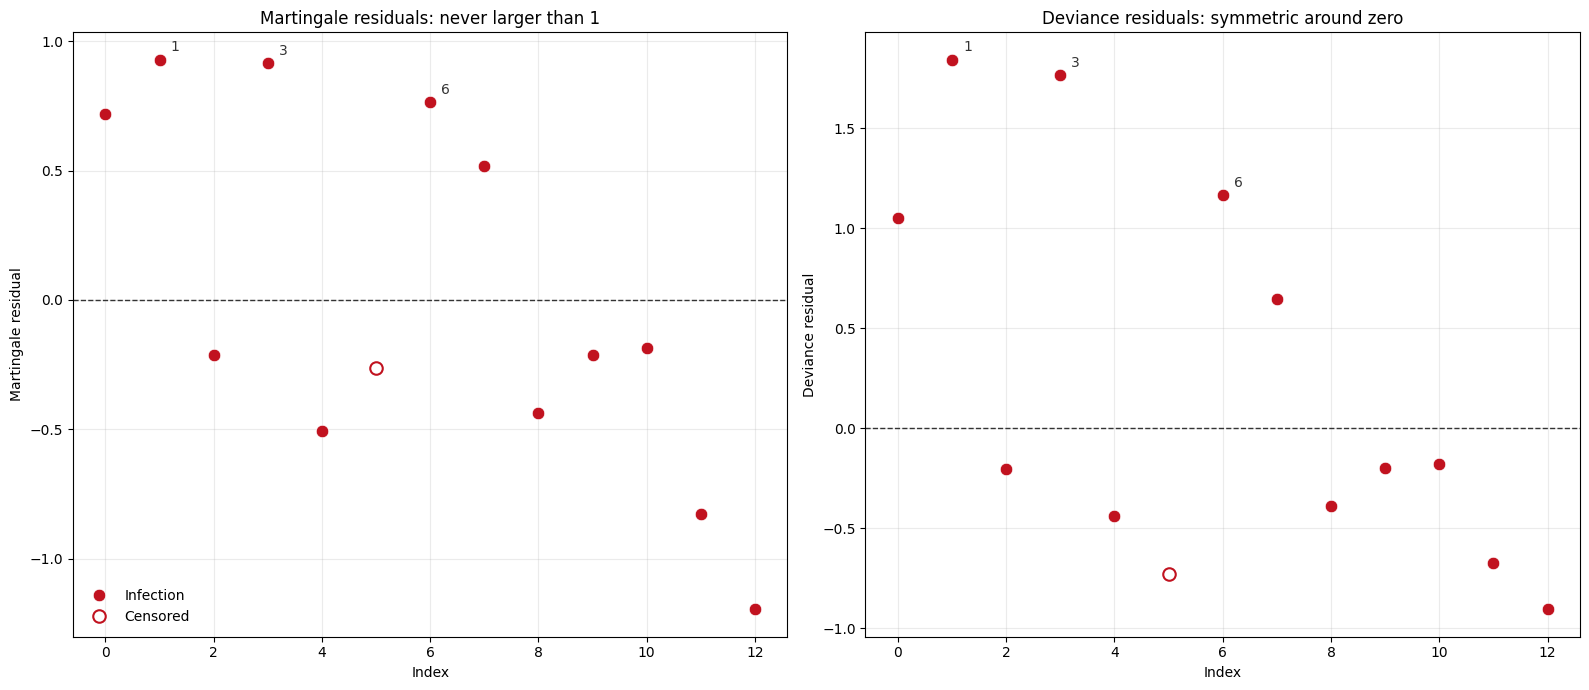

In [13]:
Largest = np.argsort(-np.abs(rD['deviance'].to_numpy()))[:3]   # the three largest deviance residuals

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, residuals, name in zip(axes, [rM['martingale'], rD['deviance']], ['Martingale', 'Deviance']):
    ax.axhline(0, color=ref_color, lw=1, ls='--')
    PlotPoints(ax, residuals.index, residuals, rM['status'])
    LabelPoints(ax, residuals.index, residuals, residuals.index, Largest)
    ax.set_xlabel("Index")
    ax.set_ylabel(f"{name} residual")
    ax.grid(True, alpha=0.25)
axes[0].set_title("Martingale residuals: never larger than 1")
axes[1].set_title("Deviance residuals: symmetric around zero")
axes[0].legend(loc='lower left', frameon=False)
plt.tight_layout()

Against the risk score $\hat\beta^Tx_i$ we see which kind of individual is badly fitted.

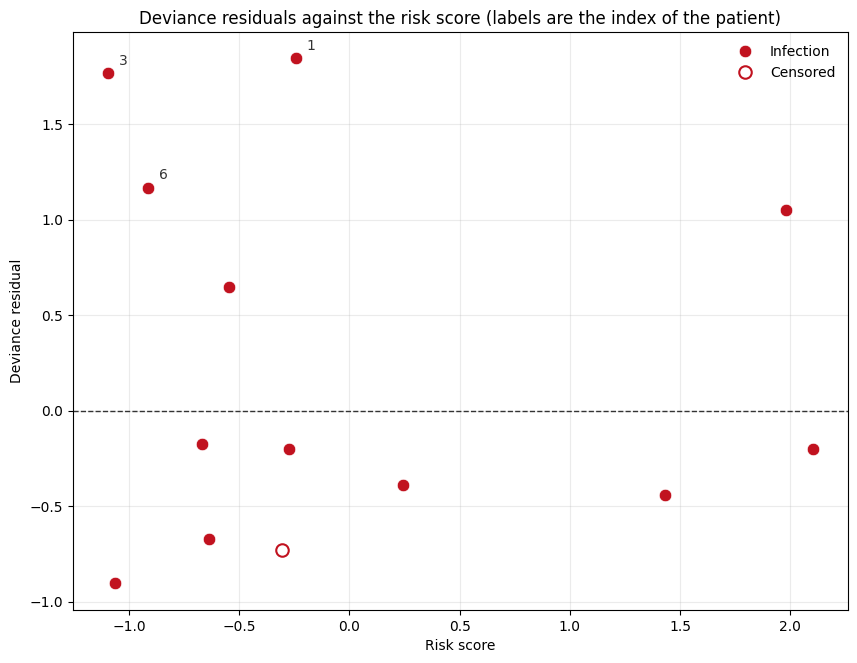

In [14]:
# The residuals come sorted by time; the risk scores are put in the same order
RiskScore = Model.predict_log_partial_hazard(DatOriginal).loc[rD.index]

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axhline(0, color=ref_color, lw=1, ls='--')
PlotPoints(ax, RiskScore, rD['deviance'], rD['status'])
LabelPoints(ax, RiskScore, rD['deviance'], rD.index, Largest)

ax.set_xlabel("Risk score")
ax.set_ylabel("Deviance residual")
ax.set_title("Deviance residuals against the risk score (labels are the index of the patient)")
ax.legend(loc='best', frameon=False)
ax.grid(True, alpha=0.25)

In [15]:
# The patients with the largest deviance residuals
DatOriginal.assign(risk_score=RiskScore, deviance=rD['deviance']).loc[rD.index[Largest]].round(3)

,time,status,age,sex,risk_score,deviance
1,15,1,44,2,-0.245,1.843
3,24,1,16,2,-1.095,1.765
6,119,1,22,2,-0.913,1.168


The three largest residuals are women who got the infection early, although the model gives women a low risk.

## Check proportional hazard assumption

There is one Schoenfeld residual for each event and each variable: the value of the variable for the individual who had the event, minus its weighted average among the individuals at risk at that time. Once scaled, $\hat\beta_j$ plus the residual estimates the coefficient $\beta_j(t)$ at that time. Under proportional hazards the coefficient does not change with time, so the points must show no trend.

In [16]:
Model.check_assumptions(DatOriginal)

Proportional hazard assumption looks okay.


[]

In [17]:
TestPH = proportional_hazard_test(Model, DatOriginal, time_transform='rank')
TestPH.summary

,test_statistic,p,-log2(p)
age,0.459842,0.497698,1.006658
sex,0.293092,0.588246,0.765509


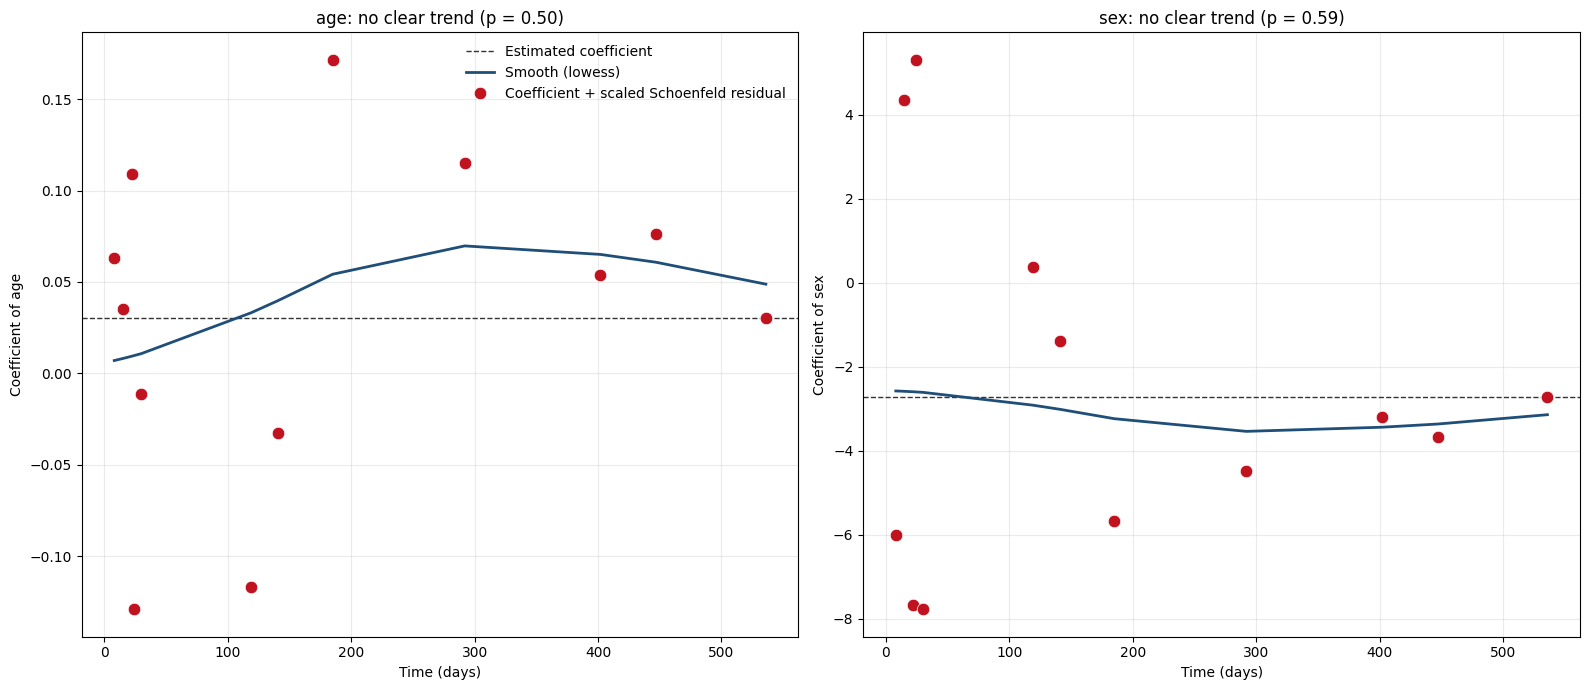

In [18]:
EventTimes = DatOriginal.loc[rSS.index, 'time']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, variable in zip(axes, rSS.columns):
    beta_t = Model.params_[variable] + rSS[variable]
    smooth = lowess(beta_t, EventTimes, frac=0.9)

    ax.axhline(Model.params_[variable], color=ref_color, lw=1, ls='--', label='Estimated coefficient')
    ax.plot(smooth[:, 0], smooth[:, 1], color=line_color, lw=2, label='Smooth (lowess)')
    ax.plot(EventTimes, beta_t, 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5,
            label='Coefficient + scaled Schoenfeld residual')
    ax.set_xlabel("Time (days)")
    ax.set_ylabel(f"Coefficient of {variable}")
    ax.set_title(f"{variable}: no clear trend (p = {TestPH.summary.loc[variable, 'p']:.2f})")
    ax.grid(True, alpha=0.25)
axes[0].legend(loc='best', frameon=False)
plt.tight_layout()